# 05 Evaluation

**Owner:** Vedant Madne (evaluation and post-processing)

The metric, the three baselines and the regression metrics. Persistence, seasonal naive and ridge
regression need no GPU, so they are **recomputed here from the raw data** and checked against the
Kaggle results. The networks' metrics are read from `results/` (recomputing them would need their
predictions on the validation windows, which were not kept).

In [1]:
import csv
import os
import sys
import time

import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('../src'))
import local

S = local.load_study()
C = S.C
CFG = local.config()
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.color': '#e4e3df', 'axes.spines.top': False, 'axes.spines.right': False})

device: cpu  backbone: resgru


## 1. The benchmark score

With $\mathrm{SMAPE}(p,y)=|p-y|/(\tfrac12(|p|+|y|))$: $G$ is the mean SMAPE over all cells and hours,
$E$ its mean over episode cells, and $\rho$ the Pearson correlation over episode cells (per hour,
averaged). The score is $\tfrac13\big[(1-G/2)+(1+\rho)/2+(1-E/2)\big]$ on validation (the official
weights are not disclosed). It is a composite of relative error and correlation, not an accuracy.

For $p,y>0$ and $u=\log(p/y)$, $\mathrm{SMAPE}=2|\tanh(u/2)|$: twice too high and half too low cost the same.

In [2]:
rng = np.random.default_rng(0)
p, y = rng.uniform(0.1, 2000, 100000), rng.uniform(0.1, 2000, 100000)
smape = np.abs(p - y) / (0.5 * (p + y))
print('max |SMAPE - 2|tanh(u/2)|| =', float(np.abs(smape - 2 * np.abs(np.tanh(np.log(p / y) / 2))).max()))
print('cost of 2x too high:', round(float(2 * np.tanh(np.log(2) / 2)), 3), '| cost of 2x too low:', round(float(2 * np.tanh(np.log(0.5) / 2) * -1), 3))

max |SMAPE - 2|tanh(u/2)|| = 4.440892098500626e-16
cost of 2x too high: 0.667 | cost of 2x too low: 0.667


## 2. Baselines recomputed from the raw data

In [3]:
stats = S.build_stats()
months, static = S.load_months(stats)
train = S.PM25Windows(months, static, stats, 'train')
val = S.PM25Windows(months, static, stats, 'val')
tgt, msk, per = S.val_truth(val)
ts = S.truth_stats(tgt, msk)
raw = {k: np.load(os.path.join(C.RAW, k, 'cpm25.npy'), mmap_mode='r') for k in val.keys}
sn, _ = S.seasonal_naive(val, raw)
print(f'{len(val)} validation windows, {ts["n"]:,} values; truth mean {ts["mean"]:.2f} ug/m3')


def metrics(pred):
    m = S.reg_metrics(pred, tgt, msk, ts)
    m.update(S.terms_of(S.wh_terms(pred, tgt, msk)))
    return m


local_res = {'persistence': metrics(per), 'seasonal_naive': metrics(sn)}
kaggle_res = local.load_json('baselines', 'baselines.json')['models']
for k in local_res:
    a, b = local_res[k], kaggle_res[k]
    print(f"{k:15s} MAE {a['mae']:.3f} RMSE {a['rmse']:.3f} R2 {a['r2']:.4f} score {a['score']:.5f}   "
          f"Kaggle: {b['mae']:.3f} {b['rmse']:.3f} {b['r2']:.4f} {b['score']:.5f}")

  APRIL_16: T=715  ep_ratio=0.0208


  JULY_16: T=739  ep_ratio=0.0197


  OCT_16: T=739  ep_ratio=0.0170


  DEC_16: T=739  ep_ratio=0.0217


  train: 2257 windows  ep_density mean=0.0201
  val hour estimation: <=1h 0.977
  val: 214 windows  ep_density mean=0.0182


214 validation windows, 59,440,640 values; truth mean 36.16 ug/m3


persistence     MAE 10.439 RMSE 26.457 R2 0.7673 score 0.85154   Kaggle: 10.439 26.457 0.7673 0.85154
seasonal_naive  MAE 11.532 RMSE 26.797 R2 0.7613 score 0.79069   Kaggle: 11.532 26.797 0.7613 0.79069


## 3. Ridge regression, refitted here

One linear model shared by every cell: 30 features (the 20 channels at the last input hour, log PM2.5 at
the 9 earlier hours, a bias) predict the 16 changes of log PM2.5 from the last hour. It is fitted in
closed form on every fourth cell of every training window; the penalty is chosen on validation.

In [4]:
t0 = time.time()
xtx, xty, n = S.ridge_fit(train)
items = [val[i] for i in range(len(val))]
grid = {}
for lam in CFG['ridge']['lambdas']:
    w = S.ridge_weights(xtx, xty, lam)
    pred = np.stack([S.ridge_predict(it[0], it[3], w) for it in items])
    grid[lam] = (S.terms_of(S.wh_terms(pred, tgt, msk))['score'], w, pred)
best = max(grid, key=lambda l: grid[l][0])
rm = metrics(grid[best][2])
kr = local.load_json('ridge', 'ridge.json')
print(f'fitted on {n:,} cell-windows in {(time.time() - t0) / 60:.1f} min; validation score by penalty:',
      {f'{l:g}': round(v[0], 5) for l, v in grid.items()})
print(f"best penalty {best:g}: MAE {rm['mae']:.3f} RMSE {rm['rmse']:.3f} R2 {rm['r2']:.4f} score {rm['score']:.5f}")
print(f"Kaggle run:   penalty {kr['model']['lam']:g}: MAE {kr['model']['mae']:.3f} RMSE {kr['model']['rmse']:.3f} R2 {kr['model']['r2']:.4f} score {kr['model']['score']:.5f}")
print('largest weight difference from the Kaggle run:', float(np.abs(grid[best][1] - np.array(kr['weights'])).max()))
del items, months

fitted on 2,448,845 cell-windows in 0.3 min; validation score by penalty: {'0.01': 0.8637, '1': 0.8637, '100': 0.86368, '10000': 0.86227, '1e+06': 0.85753}
best penalty 0.01: MAE 8.507 RMSE 21.482 R2 0.8466 score 0.86370
Kaggle run:   penalty 0.01: MAE 8.507 RMSE 21.482 R2 0.8466 score 0.86370
largest weight difference from the Kaggle run: 5.397102869897363e-07


## 4. All models on validation

The networks' metrics come from the regression-metrics run on Kaggle, which recomputed every model's
benchmark score and matched its logged value. Skill is how much lower the RMSE is than persistence's.

In [5]:
R = local.load_json('regression', 'regression_metrics.json')['models']
rows = [('persistence', local_res['persistence']), ('seasonal naive', local_res['seasonal_naive']), ('ridge regression', rm)]
rows += [(R[k]['label'], R[k]) for k in ('patchafno_s42', 'convlstm_s42', 'fmgwaclu_s42', 'afnov4_s42', 'resgru_s42',
                                         'afnov4_5seed', 'afnov4_5seed_cal_lomo', 'resgru_5seed', 'resgru_5seed_cal_lomo')]
p_rmse = local_res['persistence']['rmse']
print(f"{'model':48s} {'MAE':>7s} {'RMSE':>7s} {'R2':>7s} {'skill':>7s} {'score':>8s}")
for name, m in rows:
    print(f"{name:48s} {m['mae']:7.2f} {m['rmse']:7.2f} {m['r2']:7.3f} {100 * (1 - m['rmse'] / p_rmse):6.1f}% {m['score']:8.4f}")

model                                                MAE    RMSE      R2   skill    score
persistence                                        10.44   26.46   0.767    0.0%   0.8515
seasonal naive                                     11.53   26.80   0.761   -1.3%   0.7907
ridge regression                                    8.51   21.48   0.847   18.8%   0.8637
patch AFNO seed 42                                  6.85   19.02   0.880   28.1%   0.9031
ConvLSTM seed 42                                    7.05   18.93   0.881   28.5%   0.8945
FMG-WACLU seed 42                                   7.14   19.32   0.876   27.0%   0.9099
AFNO V4 seed 42                                     7.31   20.17   0.865   23.8%   0.9110
ResGRU-UNet seed 42                                 6.57   18.57   0.885   29.8%   0.9158
AFNO V4 5-seed mean                                 6.99   19.45   0.874   26.5%   0.9145
AFNO V4 5-seed + cal (leave-one-month-out)          7.76   20.90   0.855   21.0%   0.9149
ResGRU-UNe

## 5. Calibration trades error for score

After ensembling, each lead hour is multiplied by a factor fitted on validation (grid 0.90 to 1.10) to
maximize the SMAPE terms. Episode cells are chosen where the truth turned out high, so shifting up helps
the episode terms, while absolute and squared errors get worse.

In [6]:
for f, name in (('afnov4', 'AFNO V4'), ('resgru', 'ResGRU-UNet')):
    a, c = R[f'{f}_5seed'], R[f'{f}_5seed_cal_lomo']
    print(f'{name:12s} plain: MAE {a["mae"]:.2f}, R2 {a["r2"]:.3f}, score {a["score"]:.4f} -> calibrated (leave one month out): '
          f'MAE {c["mae"]:.2f}, R2 {c["r2"]:.3f}, score {c["score"]:.4f}')
print('in-sample factors by lead hour, ResGRU-UNet:', R['resgru_5seed_cal_in']['scales'])

AFNO V4      plain: MAE 6.99, R2 0.874, score 0.9145 -> calibrated (leave one month out): MAE 7.76, R2 0.855, score 0.9149
ResGRU-UNet  plain: MAE 6.32, R2 0.892, score 0.9193 -> calibrated (leave one month out): MAE 7.12, R2 0.871, score 0.9210
in-sample factors by lead hour, ResGRU-UNet: [1.01, 1.0, 1.01, 1.01, 1.02, 1.02, 1.03, 1.04, 1.05, 1.06, 1.07, 1.08, 1.09, 1.1, 1.1, 1.1]


## 6. By lead hour

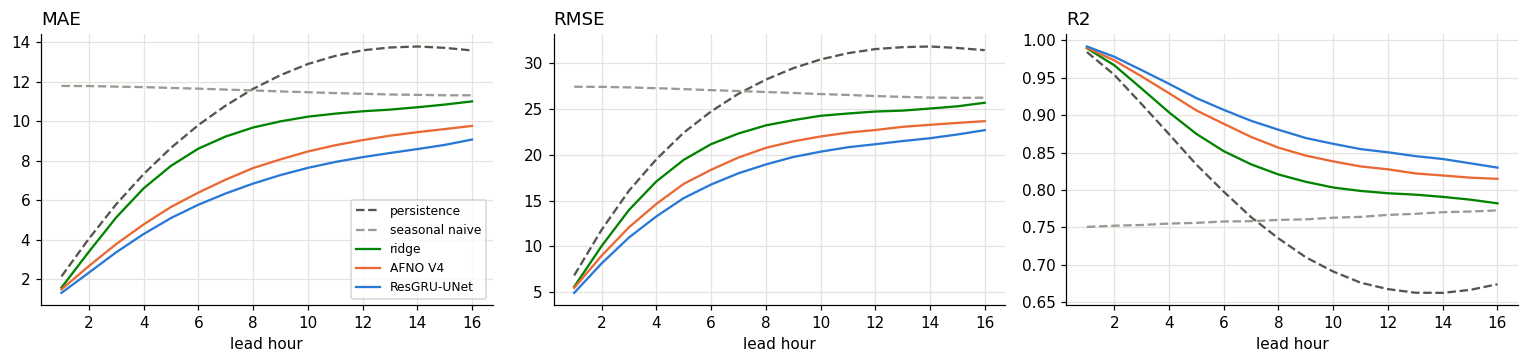

In [7]:
hrs = np.arange(1, 17)
series = [('persistence', local_res['persistence'], '#55554f', '--'), ('seasonal naive', local_res['seasonal_naive'], '#9a9a93', '--'),
          ('ridge', rm, '#008300', '-'), ('AFNO V4', R['afnov4_5seed'], '#eb6834', '-'), ('ResGRU-UNet', R['resgru_5seed'], '#2a78d6', '-')]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
for k, key in enumerate(('mae', 'rmse', 'r2')):
    for name, m, col, ls in series:
        ax[k].plot(hrs, m['per_hour'][key], color=col, ls=ls, label=name)
    ax[k].set_title(key.upper() if key != 'r2' else 'R2', loc='left'); ax[k].set_xlabel('lead hour')
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 7. The held-out test set

Test answers are hidden, so the test set gives only the benchmark score (no MAE, RMSE or R2).

In [8]:
for r in csv.DictReader(open(local.result('test_scores.csv'))):
    if any(k in r['description'] for k in ('baseline', '5-seed mean', 'seed 42, val')):
        print(f"{r['private_score']}  {r['description']}")

0.8798  backbone study: ResGRU-UNet in the V4 pipeline, seed 42, val 0.9158
0.8452  backbone study: ConvLSTM in the V4 pipeline, seed 42, val 0.8945
0.8710  backbone study: FMG-WACLU in the V4 pipeline, seed 42, val 0.9099
0.8530  backbone study: patch AFNO (B14 fixed) in the V4 pipeline, seed 42, val 0.9031
0.8848  backbone study 5 seeds: AFNO V4 5-seed mean + V4 per-horizon calibration, val 0.9158 (in sample)
0.8914  backbone study 5 seeds: ResGRU-UNet 5-seed mean + V4 per-horizon calibration, val 0.9215 (in sample)
0.8793  backbone study 5 seeds: AFNO V4 5-seed mean, no calibration, val 0.9145
0.8838  backbone study 5 seeds: ResGRU-UNet 5-seed mean, no calibration, val 0.9193
0.7910  backbone study baseline: persistence (last input hour repeated for 16 h), no model, val 0.8515
0.7951  backbone study baseline: ridge regression (20 channels last hour + PM history), val 0.8637
